In [3]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.lib.distances import distance_array

TOP  = "md_TCBP_0_1.gro"      # структура всей системы с лигандом (33495 атомов)
TRAJ = "600-ns.xtc"     # склеенная траектория
CUT  = 4.5                # Å = 0.45 нм
STEP = 5                  # каждый 5-й кадр

u = mda.Universe(TOP, TRAJ)
print("atoms:", u.atoms.n_atoms, " frames:", len(u.trajectory),
      " the end, ns:", u.trajectory[-1].time / 1000)

pep1 = u.atoms[:256].select_atoms("not name H*")
pep2 = u.atoms[256:512].select_atoms("not name H*")
lig  = u.atoms[512:544].select_atoms("not name H*")
print("heavy atoms:", len(pep1), len(pep2), len(lig))
print("ligand:", u.atoms[512:544].resnames[0])

atoms: 33495  frames: 300001  the end, ns: 600.0
heavy atoms: 139 139 26
ligand: TCB


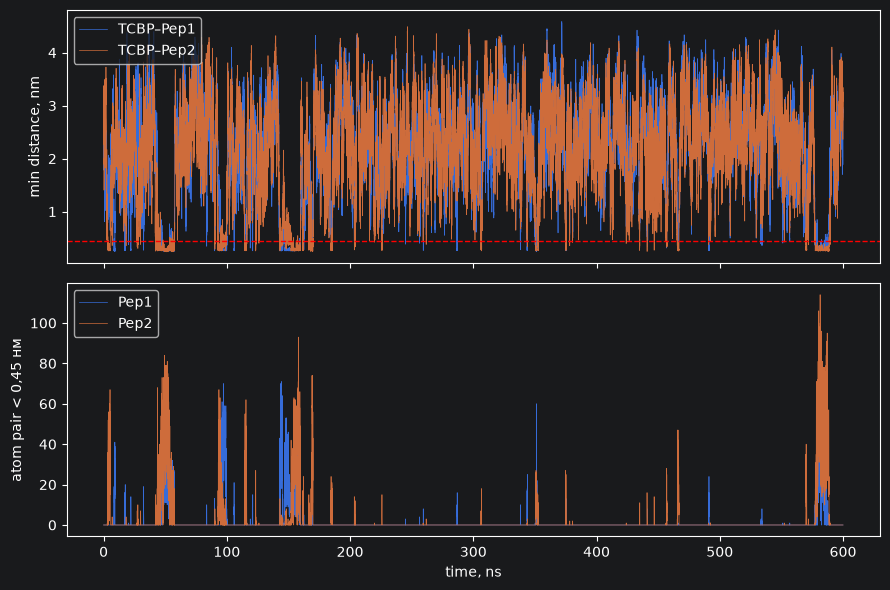

ligand-any peptide contact fraction: 0.11
with Pep1: 0.08, with Pep2: 0.09


In [5]:
t, d1, d2, n1, n2 = [], [], [], [], []
for ts in u.trajectory[::STEP]:
    a = distance_array(lig.positions, pep1.positions, box=ts.dimensions)
    b = distance_array(lig.positions, pep2.positions, box=ts.dimensions)
    t.append(ts.time / 1000)
    d1.append(a.min() / 10); d2.append(b.min() / 10)    # Å -> нм
    n1.append((a < CUT).sum()); n2.append((b < CUT).sum())

t, d1, d2, n1, n2 = map(np.array, (t, d1, d2, n1, n2))

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, d1, lw=0.5, label="TCBP–Pep1")
ax[0].plot(t, d2, lw=0.5, label="TCBP–Pep2")
ax[0].axhline(CUT / 10, color="r", ls="--", lw=1)
ax[0].set_ylabel("min distance, nm"); ax[0].legend()
ax[1].plot(t, n1, lw=0.5, label="Pep1")
ax[1].plot(t, n2, lw=0.5, label="Pep2")
ax[1].set_ylabel("atom pair < 0,45 нм"); ax[1].set_xlabel("time, ns"); ax[1].legend()
fig.tight_layout(); fig.savefig("tcbp_contacts.png", dpi=200); plt.show()

bound = (d1 < CUT/10) | (d2 < CUT/10)
print(f"ligand-any peptide contact fraction: {bound.mean():.2f}")
print(f"with Pep1: {(d1 < CUT/10).mean():.2f}, with Pep2: {(d2 < CUT/10).mean():.2f}")